<a href="https://colab.research.google.com/github/yashikasgh/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yashikasgh/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

### Research question

Can a transparent rule-based content-refresh score prioritize pages for human review more effectively than a Logistic Regression model, particularly when evaluated on clients not seen during training?

### Decision this supports

Content editors have limited time to review existing pages. This project explores how observable signals—content staleness, search impressions, and click-through rate (CTR)—can help prioritize which pages to inspect first.

### Evaluation approach

I compare a rule-based baseline with Logistic Regression using Precision@K and Average Precision. Both approaches are evaluated on the same test split, with random and client-grouped validation compared to understand how performance changes when test clients are unseen during training.

The goal is a transparent decision-support workflow, not an autonomous content-publishing system.

In [1]:

# Section 1: Research question and decision
research_question = (
    "Can a transparent rule-based content-refresh score prioritize pages "
    "for human review more effectively than Logistic Regression, especially "
    "on clients not seen during training?"
)

evaluation_metrics = ["Precision@K", "Average Precision"]
validation_designs = ["Random split", "Client-grouped split"]

print("Research question:")
print(research_question)
print("\nEvaluation metrics:", evaluation_metrics)
print("Validation designs:", validation_designs)


Research question:
Can a transparent rule-based content-refresh score prioritize pages for human review more effectively than Logistic Regression, especially on clients not seen during training?

Evaluation metrics: ['Precision@K', 'Average Precision']
Validation designs: ['Random split', 'Client-grouped split']


## 2. Data

### Dataset and scope

This project uses the anonymized FlyRank content-refresh starter dataset, `content_refresh_anonymized.csv`, containing 30,000 content records and 44 columns. The dataset includes content characteristics, search-performance aggregates, freshness indicators, engagement-related fields, and trend labels.

The analysis is based on the starter dataset used in the internship workflow, not the full warehouse release. Results should therefore be interpreted as an evaluation of this dataset and workflow rather than as a measurement across all production search data.

### Features used

The Logistic Regression experiment used the following feature groups:

- **Numeric:** search volume, competition, cost per click (CPC), word count, character count, content age, and days since last update.
- **Categorical:** competition level, content type, main intent, age tier, freshness tier, word-count tier, and character-count tier.

The target label was `is_down`, defined as whether `trend_direction` equals `down`. The target column and `trend_pct` were excluded from the model's input features.

### Exclusions and data-quality considerations

Identifiers such as `content_id` and `client_id` were not used as predictive features. Recent and previous 30-day metrics were excluded from the Logistic Regression feature list to reduce the risk of directly encoding the outcome.

The exact construction and observation window of the trend label have not been independently verified. Some 90-day aggregate features could overlap with the period used to construct that label. Consequently, the feature exclusions reduce some leakage risks but do not establish that the experiment is free from temporal leakage.

### Date windows and provenance

The analysis uses the supplied anonymized starter snapshot. The exact underlying date windows for every feature and the target label were not established in this experiment. No more specific date range is claimed here.

The public report excludes client names, private URLs, raw search queries, credentials, and row-level data exports.

In [3]:

from pathlib import Path
import pandas as pd

csv_path = Path("/content/content_refresh_anonymized.csv")

if not csv_path.exists():
    matches = list(Path("/content").rglob("content_refresh_anonymized.csv"))
    if not matches:
        raise FileNotFoundError(
            "Upload content_refresh_anonymized.csv to Colab, then rerun."
        )
    csv_path = matches[0]

data_df = pd.read_csv(csv_path)

print("Dataset file:", csv_path.name)
print("Rows:", data_df.shape[0])
print("Columns:", data_df.shape[1])
print("Unique content IDs:", data_df["content_id"].nunique())
print("\nTarget label source:")
print(data_df["trend_direction"].value_counts(dropna=False))
print("\nMissing values in key columns:")
key_cols = [
    "content_id", "client_id", "trend_direction",
    "impressions_90d", "ctr", "days_since_last_update"
]
display(data_df[key_cols].isna().sum().to_frame("missing_values"))


Dataset file: content_refresh_anonymized.csv
Rows: 18698
Columns: 44
Unique content IDs: 18698

Target label source:
trend_direction
down      10072
stable     3775
up         2737
new        1384
flat        729
NaN           1
Name: count, dtype: int64

Missing values in key columns:


,missing_values
content_id,0
client_id,1
trend_direction,1
impressions_90d,1
ctr,1
days_since_last_update,1


## 3. Methodology

### Rule-based baseline

The baseline assigns a score from 0 to 100 using three transparent rules:

- **STALE (40 points):** `days_since_last_update >= 180`.
- **HIGH_VISIBILITY (40 points):** `impressions_90d` is greater than or equal to the dataset median.
- **LOW_CTR (20 points):** `ctr` is below the dataset median.

The three signals are added to produce a ranking score. Pages with higher scores are reviewed first. In this dataset, the observed medians were 731 impressions and 0.07 CTR.

### Logistic Regression

A Logistic Regression classifier was trained to predict whether a record had `trend_direction == "down"`. Numeric inputs included search volume, competition, CPC, word count, character count, content age, and days since last update. Categorical inputs included competition level, content type, main intent, age tier, freshness tier, word-count tier, and character-count tier.

Identifiers, the target column, `trend_pct`, recent/previous 30-day metrics, and the baseline score were excluded from the model inputs. The model was compared with the rule-based baseline as a ranking method.

### Validation design

Two validation strategies were compared:

1. **Random split:** records were randomly divided into training and test sets. Because records from the same clients can appear in both sets, this split may not represent performance on entirely unseen clients.
2. **Client-grouped split:** clients were assigned exclusively to either the training or test set. This avoids client overlap between the two sets and provides a more demanding test of generalization to unseen clients.

The model and baseline were evaluated on the same test set within each strategy.

### Evaluation metrics

- **Precision@K:** the proportion of the top K ranked records that have the target label.
- **Average Precision (AP):** a summary of precision across recall levels, useful for evaluating ranked binary predictions.

Random-split and grouped-split metrics are reported separately because the two test sets differ in composition and difficulty.

### Leakage and validity checks

The feature list excludes the target label, `trend_pct`, row identifiers, client identifiers, recent/previous 30-day metrics, and the baseline score. The grouped split was checked to ensure that no client appeared in both training and test sets.

However, the exact time window used to construct `trend_direction` has not been verified. Some aggregate features may overlap with the target observation period, so temporal leakage remains a limitation. These checks do not establish that the model is leakage-free.

In [4]:

# Section 3: Methodology summary
baseline_rules = {
    "STALE": "days_since_last_update >= 180 -> +40",
    "HIGH_VISIBILITY": "impressions_90d >= dataset median -> +40",
    "LOW_CTR": "ctr < dataset median -> +20",
}

numeric_features = [
    "search_volume", "competition", "cpc", "word_count",
    "char_count", "content_age_days", "days_since_last_update"
]

categorical_features = [
    "competition_level", "content_type", "main_intent", "age_tier",
    "freshness_tier", "word_count_tier", "char_count_tier"
]

excluded_from_model = [
    "trend_direction", "trend_pct", "content_id", "client_id",
    "baseline_score", "recent/previous 30-day metrics"
]

print("Baseline rules:")
for rule, definition in baseline_rules.items():
    print(f"- {rule}: {definition}")

print("\nNumeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Excluded inputs:", ", ".join(excluded_from_model))
print("\nValidation: random split and client-grouped split")
print("Metrics: Precision@K and Average Precision")


Baseline rules:
- STALE: days_since_last_update >= 180 -> +40
- HIGH_VISIBILITY: impressions_90d >= dataset median -> +40
- LOW_CTR: ctr < dataset median -> +20

Numeric features: 7
Categorical features: 7
Excluded inputs: trend_direction, trend_pct, content_id, client_id, baseline_score, recent/previous 30-day metrics

Validation: random split and client-grouped split
Metrics: Precision@K and Average Precision


## 4. Results (vs baseline)

### Results: validation strategy changes the conclusion

The random split produced more favorable results for Logistic Regression than the client-grouped split. Under random validation, Logistic Regression achieved Precision@20 of 0.80 and Average Precision of 0.651, compared with 0.75 and 0.583 for the rule-based baseline.

When clients were held out entirely from training, the rule-based baseline achieved Precision@20 of 0.60 and Average Precision of 0.520. Logistic Regression achieved 0.30 and 0.514, respectively. Thus, Logistic Regression did not outperform the baseline on the grouped split.

These results suggest that random validation may give an overly optimistic picture of performance on unseen clients. They do not, by themselves, prove that the model memorized client-specific patterns. The grouped test set contained eight held-out clients, and differences in client composition may also affect results.

### Metric comparison

Precision@K measures the proportion of pages labeled as declining among the top K ranked pages. Average Precision summarizes ranking quality across recall levels. The positive-label rate was 0.542 in the random test set and 0.517 in the grouped test set, so the test populations were not identical.

The practical takeaway is to retain the transparent rule-based baseline for this experiment and require stronger, leakage-aware validation before adopting the learned model for unseen-client prioritization.

,Split,Method,Precision@20,Precision@50,Average Precision
0,Random,Rule-based baseline,0.75,0.72,0.583
1,Random,Logistic Regression,0.80,0.74,0.651
2,Client-grouped,Rule-based baseline,0.60,0.56,0.520
3,Client-grouped,Logistic Regression,0.30,0.38,0.514


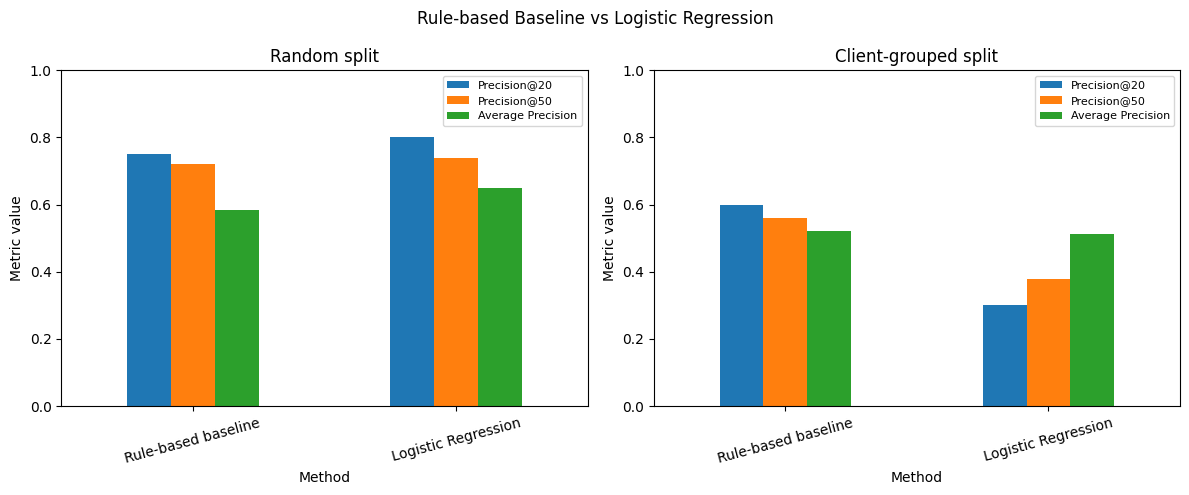

Chart saved to: work/figures/model_vs_baseline.png


In [5]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

results = pd.DataFrame([
    {"Split": "Random", "Method": "Rule-based baseline",
     "Precision@20": 0.75, "Precision@50": 0.72, "Average Precision": 0.583},
    {"Split": "Random", "Method": "Logistic Regression",
     "Precision@20": 0.80, "Precision@50": 0.74, "Average Precision": 0.651},
    {"Split": "Client-grouped", "Method": "Rule-based baseline",
     "Precision@20": 0.60, "Precision@50": 0.56, "Average Precision": 0.520},
    {"Split": "Client-grouped", "Method": "Logistic Regression",
     "Precision@20": 0.30, "Precision@50": 0.38, "Average Precision": 0.514},
])

display(results)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, split in zip(axes, ["Random", "Client-grouped"]):
    subset = results[results["Split"] == split].set_index("Method")
    subset[["Precision@20", "Precision@50", "Average Precision"]].plot(
        kind="bar", ax=ax
    )
    ax.set_title(f"{split} split")
    ax.set_ylabel("Metric value")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=15)
    ax.legend(fontsize=8)

fig.suptitle("Rule-based Baseline vs Logistic Regression")
fig.tight_layout()

figures_dir = Path("work/figures")
figures_dir.mkdir(parents=True, exist_ok=True)
chart_path = figures_dir / "model_vs_baseline.png"
fig.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)


## 5. Limitations

**Starter-dataset scope.** This experiment uses 30,000 anonymized content records, not the full production warehouse. Its findings should not be generalized to all websites, clients, or search environments without further validation.

**Unverified target timing.** The target is defined as `trend_direction == "down"`, but the exact construction and observation window of this label have not been independently verified. Some aggregate input features may overlap with the target period. The leakage audit reduced several obvious risks but did not rule out temporal leakage.

**Validation uncertainty.** The client-grouped test set contains eight held-out clients. Its results are more relevant to unseen-client generalization than the random split, but the small number of held-out clients limits how confidently the result can be generalized.

**Model performance.** Logistic Regression performed better on the random split but did not outperform the rule-based baseline on the grouped split. This does not prove client memorization or establish why the performance gap occurred. Differences in client composition, label prevalence, and feature distributions may contribute.

**Observational evidence.** The analysis identifies ranking signals and evaluates a label-prediction task. It does not demonstrate that refreshing a page causes traffic, ranking, or conversion improvements.

**Operational limitations.** The action queue is a prioritization aid, not a publishing decision. Scores are based on dataset-specific median thresholds and should be reviewed before use in a different environment.

### Next steps

Verify the target's time window, perform a stricter time-based evaluation if suitable timestamped data is available, validate across more held-out clients, and measure real review outcomes before claiming business impact.

In [6]:

# Section 5: Limitations checklist
limitations = {
    "starter_dataset_only": True,
    "target_window_verified": False,
    "temporal_leakage_ruled_out": False,
    "grouped_validation_has_8_heldout_clients": True,
    "causal_refresh_effect_established": False,
}

for item, status in limitations.items():
    print(f"{'VERIFIED' if status else 'NOT ESTABLISHED'}: {item}")

print(
    "\nInterpretation: report the current metrics as exploratory ranking results. "
    "Do not claim causal impact or leakage-free prediction."
)


VERIFIED: starter_dataset_only
NOT ESTABLISHED: target_window_verified
NOT ESTABLISHED: temporal_leakage_ruled_out
VERIFIED: grouped_validation_has_8_heldout_clients
NOT ESTABLISHED: causal_refresh_effect_established

Interpretation: report the current metrics as exploratory ranking results. Do not claim causal impact or leakage-free prediction.


## 6. Ranked recommendations

### Ranked recommendations: turn scores into review actions

The action playbook uses a transparent 0–100 rule-based score to prioritize human review. The score is not a prediction of business value or proof that a page needs refreshing.

**Priority 1 — Review pages with multiple signals (80–100 points).**  
Pages that are stale and have high search visibility receive 80 points or more. Review their current accuracy, search intent, title and description, and whether the content still satisfies user needs. If CTR is also below the dataset median, investigate the search snippet and intent match before proposing edits.

**Priority 2 — Investigate pages with one strong signal (40–60 points).**  
A stale page or a high-visibility page with weaker CTR-related signals may warrant further inspection. Determine whether the issue is content freshness, search presentation, ranking position, or another factor before deciding on a change.

**Priority 3 — Monitor pages with fewer priority signals (0–20 points).**  
These pages should not automatically be considered healthy. Monitor them according to their purpose and business importance, and investigate if additional evidence suggests a problem.

### Observed queue distribution

Across 30,000 records, 15 pages (0.05%) received the highest-priority category, 15,151 received the secondary-review category, and 14,834 were assigned to monitoring. The very small top-priority group means the current rules produce a narrow first-pass queue, while the secondary-review category remains large.

### Recommended operating procedure

1. Start with the highest-scoring pages and confirm that the signals are meaningful.
2. Record the reviewer's decision and reason for each page.
3. Estimate potential value, effort, and risk before editing.
4. Make approved changes manually and document them.
5. Compare outcomes over consistent observation windows, accounting for seasonality and other possible influences.
6. Reassess thresholds using documented evidence and reviewer capacity.

The recommended first step is a small human-reviewed pilot—not automatic publishing. The queue should be expanded only if reviewers find the recommendations useful and the process can be evaluated responsibly.

In [7]:

# Section 6: Ranked recommendations summary

recommendations = [
    {
        "priority": 1,
        "score_range": "80-100",
        "action": "PRIORITY_HUMAN_REVIEW",
        "reason": "Multiple signals; inspect page quality and search intent."
    },
    {
        "priority": 2,
        "score_range": "40-60",
        "action": "SECONDARY_HUMAN_REVIEW",
        "reason": "Investigate the relevant signal before proposing changes."
    },
    {
        "priority": 3,
        "score_range": "0-20",
        "action": "MONITOR",
        "reason": "Monitor; do not assume the page is healthy."
    },
]

recommendations_df = pd.DataFrame(recommendations)
display(recommendations_df)

print("Observed queue distribution:")
print("Priority review: 15 pages (0.05%)")
print("Secondary review: 15,151 pages")
print("Monitor: 14,834 pages")
print("\nAll recommendations require human review before action.")


,priority,score_range,action,reason
0,1,80-100,PRIORITY_HUMAN_REVIEW,Multiple signals; inspect page quality and sea...
1,2,40-60,SECONDARY_HUMAN_REVIEW,Investigate the relevant signal before proposi...
2,3,0-20,MONITOR,Monitor; do not assume the page is healthy.


Observed queue distribution:
Priority review: 15 pages (0.05%)
Secondary review: 15,151 pages
Monitor: 14,834 pages

All recommendations require human review before action.


## 7. Artifacts the paper embeds

### Research artifacts

This project produces the following artifacts to support inspection and reproducibility:

- **Model comparison chart:** `work/figures/model_vs_baseline.png` compares the rule-based baseline and Logistic Regression under random and client-grouped validation.
- **Action distribution chart:** `work/figures/action_distribution.png` shows how the 30,000 records are distributed across the three review categories.
- **Action playbook metrics:** `work/outputs/action_playbook_metrics.json` records aggregate queue counts and the thresholds used to generate the queue.
- **Action queue:** `work/outputs/refresh_action_queue.csv` contains the ranked, row-level review recommendations. This file is an internal artifact and must not be published in the public repository or embedded in the paper because it contains row-level content identifiers.
- **Analysis notebooks:** the Week 4 baseline, Week 5 model, Week 6 validation audit, Week 7 action playbook, and capstone notebook document the workflow.

The public paper should display aggregate results and public-safe charts. Readers should be able to inspect the methodology and notebook code without accessing private or row-level outputs.

In [8]:

from pathlib import Path

artifact_paths = [
    Path("work/figures/model_vs_baseline.png"),
    Path("work/figures/action_distribution.png"),
    Path("work/outputs/action_playbook_metrics.json"),
    Path("work/notebooks/capstone.ipynb"),
]

print("Artifact verification:")
for path in artifact_paths:
    status = "FOUND" if path.exists() else "NOT FOUND"
    print(f"{status}: {path}")

print("\nDo not publish this row-level file:")
print("work/outputs/refresh_action_queue.csv")


Artifact verification:
FOUND: work/figures/model_vs_baseline.png
NOT FOUND: work/figures/action_distribution.png
NOT FOUND: work/outputs/action_playbook_metrics.json
NOT FOUND: work/notebooks/capstone.ipynb

Do not publish this row-level file:
work/outputs/refresh_action_queue.csv


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.


## ML-12: Five-minute project demo

### 0:00–0:40 — Problem and motivation
Explain the practical problem: content teams cannot review every page at once. The project tests whether transparent signals can help prioritize pages for human review.

### 0:40–1:20 — Dataset and research question
Introduce the anonymized 30,000-row starter dataset. Explain that the objective is to compare a rule-based content-refresh baseline with Logistic Regression, particularly on clients not seen during training.

### 1:20–2:10 — Methodology
Walk through the three baseline rules: staleness (+40), high visibility (+40), and low CTR (+20). Explain the target label, the selected model features, and the difference between random and client-grouped validation.

### 2:10–3:10 — Results
Show the model-versus-baseline chart. Under random validation, Logistic Regression achieves Precision@20 of 0.80 compared with 0.75 for the baseline. Under client-grouped validation, the baseline achieves 0.60 compared with 0.30 for Logistic Regression. Average Precision on the grouped split is 0.520 for the baseline and 0.514 for Logistic Regression.

### 3:10–4:10 — Action playbook
Show the action-distribution chart and explain the three review categories. Of 30,000 records, 15 are assigned priority review, 15,151 secondary review, and 14,834 monitoring. Emphasize that recommendations require human review.

### 4:10–5:00 — Limitations and conclusion
Explain that the target's exact time window is not verified, temporal leakage has not been ruled out, and grouped validation covers eight held-out clients. Conclude that the rule-based baseline is the more defensible starting point in this experiment, while further validation is needed before deployment.

###ML-12 — Social post

## Social Post
I built a content-refresh prioritization workflow as part of the FlyRank ML Internship.

Using an anonymized dataset of 30,000 content records, I compared a transparent rule-based baseline with Logistic Regression and evaluated both using random and client-grouped validation.

The key finding: Logistic Regression looked stronger under random validation, but the rule-based baseline performed better on the grouped test set, where clients were held out from training.

This reinforced an important ML lesson for me: validation design can change the conclusion. A promising score is not enough without testing how well a model generalizes.

The project includes a ranked human-review playbook, model-comparison charts, leakage checks, and documented limitations.

Built on the FlyRank ML Internship dataset. More details and reproducible analysis: (https://yashikasgh.github.io/flyrank-ml-internship/)

##Three-sentence employer summary

I built an explainable content-refresh prioritization workflow using a 30,000-record anonymized dataset, comparing a rule-based baseline with Logistic Regression. I evaluated both using random and client-grouped validation, finding that Logistic Regression's apparent advantage under random splitting did not hold on unseen clients, where the baseline achieved better Precision@20. The project includes a ranked human-review playbook, evaluation charts, leakage checks, and explicit limitations to support responsible, reproducible decision-making.